# Prueba Intertrimestral

**Nombre:**  
**Apellidos:**  

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [11]:
def rental_fee(duration_min, bike_type, is_member):

    if bike_type not in ("classic", "electric"):
        raise ValueError("El tipo de bicicleta debe ser 'classic' o 'electric'.")
    
    if bike_type == "classic":
        tarifa = 1.00
        coste = 0.05
    else:  # "electric"
        tarifa = 1.50
        coste = 0.08
    
    coste_total = tarifa + (duration_min * coste)
    
    #descuento si es miembro
    if is_member:
        coste_total *= 0.80  # 20%
        
    return round(coste_total, 2)

rental_fee(5,"classic",True)

1.0

b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [9]:
def demand_label(total_rentals, threshold):
    
    if total_rentals >= threshold:
        return "Alta"
    elif total_rentals >= (threshold / 2):
        return "Media"
    else:
        return "Baja"

demand_label(10,30)


'Baja'

c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [17]:
np.random.seed(30)
n_rows = 10

tripsDemo = pd.DataFrame({
    "duration_min": np.random.uniform(2.0, 50.0, n_rows),
    "bike_type": np.random.choice(["classic", "electric"], n_rows),
    "is_member": np.random.choice([True, False], n_rows),
    "total_rentals": np.random.randint(10, 50, n_rows)
})
fees=[]
demands=[]
threshold=40

for i in range(len(tripsDemo)):
    # Calcular tarifa con la función rental_fee
    fee = rental_fee(
        tripsDemo.loc[i, "duration_min"], 
        tripsDemo.loc[i, "bike_type"], 
        tripsDemo.loc[i, "is_member"]
    )
    fees.append(fee)
    
    # Calcular etiqueta de demanda con la función demand_label
    demand = demand_label(tripsDemo.loc[i, "total_rentals"], threshold)
    demands.append(demand)

# Asignar al DataFrame
tripsDemo["fee"] = fees
tripsDemo["demand"] = demands

print(tripsDemo)

   duration_min bike_type  is_member  total_rentals   fee demand
0     32.918890  electric      False             43  4.13   Alta
1     20.275928   classic       True             38  1.61  Media
2     33.826299   classic      False             37  2.69  Media
3      9.855235   classic       True             24  1.19  Media
4     48.205175   classic       True             21  2.73  Media
5     18.639768   classic      False             41  1.93   Alta
6     49.604048   classic      False             47  3.48   Alta
7     13.282779   classic      False             21  1.66  Media
8     30.113325   classic       True             49  2.00   Alta
9     21.521125   classic      False             19  2.08   Baja


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [ ]:
class MicromobilityTools:    

    def __init__(self, duration_min, bike_type, is_member):
        #Inicializa la clase con los datos de los viajes
        
        self.duration_min = np.array(duration_min)
        self.bike_type = np.array(bike_type)
        self.is_member = np.array(is_member)


    def calcular_tarifas(self, duration_min, bike_type, is_member):
        #Calcula la tarifa de cada viaje
         tarifa= rental_fee(duration_min, bike_type, is_member)

        tarifas = np.zeros(len(self.duration_min))
        

        return np.round(fares, 2)

    def etiqueta(self, total_rentals, threshold):
        #Etiqueta el nivel de demanda ('High' o 'Low')
        rentals_array = np.array(total_rentals)
        labels = demand_label (total_rentals, threshold)
        return labels


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [21]:
mobilityData = pd.read_csv('city_micromobility_hourly.csv')

#head muestra las primeras 5 filas 

print(mobilityData.head())


mobilityData.shape
#abajo se imprime que tiene 17520 filas y 23 columnas

              datetime  year  month  day  hour  weekday  season  is_holiday  \
0  2025-01-01 00:00:00  2025      1    1     0        2  Winter           1   
1  2025-01-01 01:00:00  2025      1    1     1        2  Winter           1   
2  2025-01-01 02:00:00  2025      1    1     2        2  Winter           1   
3  2025-01-01 03:00:00  2025      1    1     3        2  Winter           1   
4  2025-01-01 04:00:00  2025      1    1     4        2  Winter           1   

   is_weekend  is_workingday  ... wind_kmh  precip_mm  casual_users  \
0           0              0  ...      9.7        0.0             2   
1           0              0  ...      2.8        0.0             1   
2           0              0  ...      9.0        0.0             1   
3           0              0  ...      5.4        0.0             2   
4           0              0  ...      2.4        0.0             1   

   member_users  total_rentals  avg_trip_min  avg_distance_km  electric_share  \
0             8  

(17520, 23)

b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [25]:
def describeData(df):
    info = pd.DataFrame({
        "tipo": df.dtypes,
        "nulos": df.isna().sum(),
        "% nulos": (df.isna().sum() / len(df) * 100).round(2)
    })
    return info


c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [24]:
info = describeData(mobilityData)
print(info)

                    tipo  nulos  % nulos
datetime             str      0     0.00
year               int64      0     0.00
month              int64      0     0.00
day                int64      0     0.00
hour               int64      0     0.00
weekday            int64      0     0.00
season               str      0     0.00
is_holiday         int64      0     0.00
is_weekend         int64      0     0.00
is_workingday      int64      0     0.00
weather              str      0     0.00
temp_c           float64      0     0.00
humidity         float64    224     1.28
wind_kmh         float64    142     0.81
precip_mm        float64      0     0.00
casual_users       int64      0     0.00
member_users       int64      0     0.00
total_rentals      int64      0     0.00
avg_trip_min     float64    255     1.46
avg_distance_km  float64      0     0.00
electric_share   float64    182     1.04
revenue_eur      float64      0     0.00
high_demand        int64      0     0.00


Las variables humidity (1.28), wind_km (0.81), avg_trip_min(1.46) y electric_share(1.04) tienen el mayor porcentaje de valores nulos. 
Como son porcentajes bastante pequeños, ya que hay 17520 filas, no cambia demasiado los datos por lo que directamente eleminaria esos datos nulos.

d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


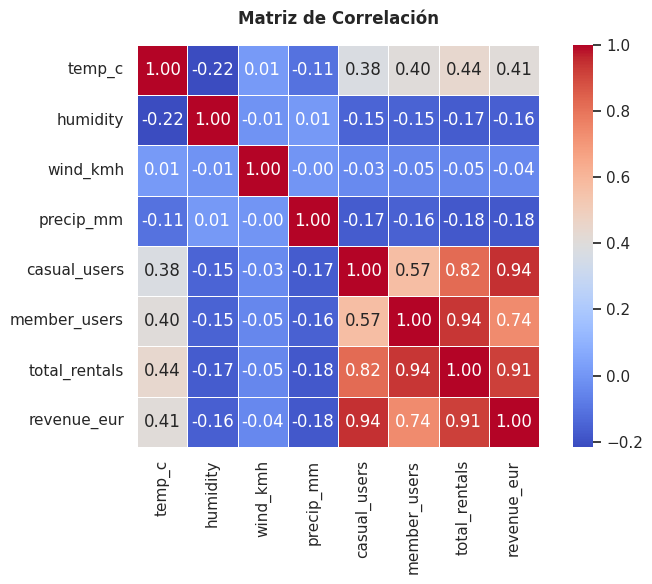

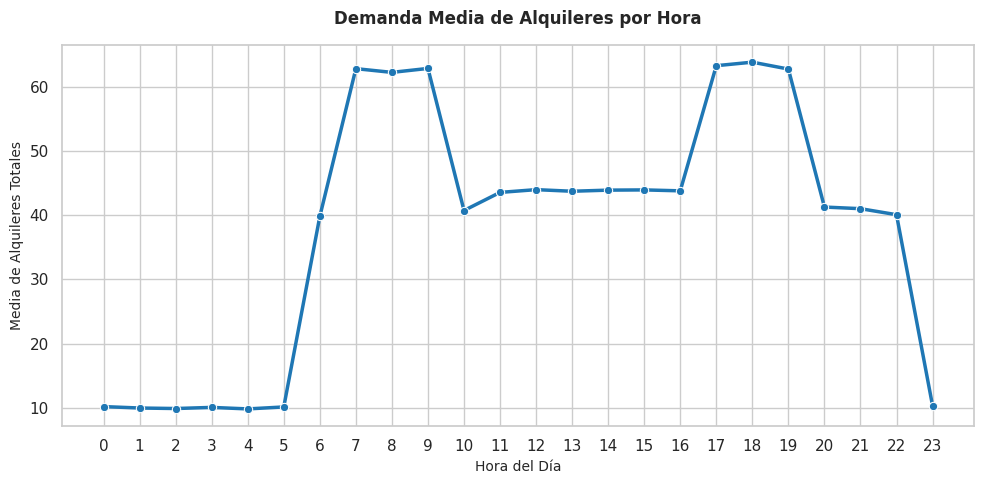

In [27]:

sns.set_theme(style="whitegrid")

# 1. Gráfico de correlación 
fig, ax = plt.subplots(figsize=(8, 6))
columnas = [
    "temp_c",
    "humidity",
    "wind_kmh",
    "precip_mm",
    "casual_users",
    "member_users",
    "total_rentals",
    "revenue_eur",
]
corr = mobilityData[columnas].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    square=True,
    ax=ax,
    linewidths=0.5,
)
ax.set_title(
    "Matriz de Correlación",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
plt.tight_layout()
plt.show()

# 2. Gráfico de demanda media por hora 
fig, ax = plt.subplots(figsize=(10, 5))

demanda = (
    mobilityData.groupby("hour")["total_rentals"]
    .mean()
    .reset_index()
)

sns.lineplot(
    data=demanda,
    x="hour",
    y="total_rentals",
    marker="o",
    linewidth=2.5,
    ax=ax,
    color="tab:blue" 
)
ax.set_title(
    "Demanda Media de Alquileres por Hora",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Hora del Día", fontsize=10)
ax.set_ylabel("Media de Alquileres Totales", fontsize=10)
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [37]:
targetVar = "total_rentals"
variables = ['hour', 'temp_c', 'humidity', 'wind_kmh']
data = mobilityData[variables + [targetVar]].copy()

data = data.dropna()

X = data[variables]
y = data[targetVar]


print(f"y: {X.shape}")
print(f"y: {y.shape}")



y: (17159, 4)
y: (17159,)


b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test:  {X_test.shape}")
print(f"Dimensiones de y_train: {y_train.shape}")
print(f"Dimensiones de y_test:  {y_test.shape}")

Dimensiones de X_train: (12011, 4)
Dimensiones de X_test:  (5148, 4)
Dimensiones de y_train: (12011,)
Dimensiones de y_test:  (5148,)


c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [39]:
# Entrenar el modelo
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

#  R² y MSE
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(f"R² en prueba: {r2:.4f}")
print(f"MSE en prueba: {mse:.4f}")

R² en prueba: 0.2807
MSE en prueba: 424.7898


Se ha obtenido un R cuadrado en prueba de 0.2807, el cual es muy bajo. Esto nos quiere decir que solo explica el 28% de los datos. Además con un MSE de 424, al predecir tiene un error promedio de 424, lo cual significa que se equivoca mucho. No es un bueno modelo.

d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [42]:
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
r2_rf = r2_score(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)

print(f"Random Forest R²: {r2_rf:.4f}")
print(f"Random Forest MSE: {mse_rf:.4f}")

Random Forest R²: 0.7583
Random Forest MSE: 142.7366


El random forest presenta un R cuadrado de 0.75, lo que significa que el modelo explica un 75% de los datos y además reduce el error más del triple, por lo cual podemos concluir que este modelo funciona mucho mejor que eo de regresión lineal. Esto demuestra que es capaz de entender patrones complejos que el otro modelo no puede idnetificar.
Random Forest funciona mejor porque combina muchos árboles de decisión para identificar patrones y relaciones complejas en los datos que los modelos simples muchas veces no logran ver. Al hacer un promedio de las respuestas de todos esos árboles, es capaz de hacer predicciones mucho más exactas y confiables.

## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [49]:
value_counts = mobilityData['high_demand'].value_counts()

print("Balance de clases:")
print(value_counts)

Balance de clases:
high_demand
0    12071
1     5449
Name: count, dtype: int64


b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [67]:
columns = ['hour', 'weekday', 'month', 
    'is_holiday', 'is_weekend', 'is_workingday',
    'temp_c', 'humidity', 'wind_kmh', 'precip_mm']

mobilityData_limpio = mobilityData.dropna(subset=columns + ['high_demand'])

X_log = mobilityData_limpio[columns]
X_log2 = pd.get_dummies(X_log, columns=columns, drop_first=True)

y_log = mobilityData_limpio["high_demand"]


X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_log, y_log, test_size=0.3, random_state=42
)

# entrenar
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_log, y_train_log)

y_pred_log = log_model.predict(X_test_log)

print(f"Accuracy: {accuracy_score(y_test_log, y_pred_log):.4f}\n")
print("Reporte de clasificación:")
print(classification_report(y_test_log, y_pred_log))

Accuracy: 0.7521

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.77      0.91      0.83      3532
           1       0.67      0.41      0.51      1616

    accuracy                           0.75      5148
   macro avg       0.72      0.66      0.67      5148
weighted avg       0.74      0.75      0.73      5148



c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


Accuracy: 0.7521

Matriz de Confusión:
[[3205  327]
 [ 949  667]]


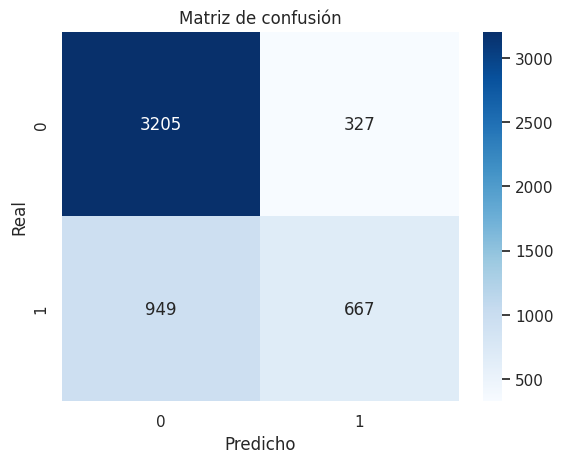

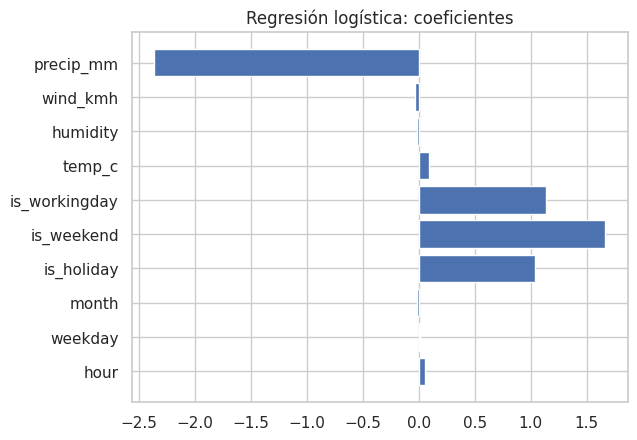

In [72]:
#accuracy
accuracy = accuracy_score(y_test_log, y_pred_log)
print(f"Accuracy: {accuracy:.4f}\n")

#Matriz de Confusión
cm = confusion_matrix(y_test_log, y_pred_log)
print("Matriz de Confusión:")
print(cm)


sns.heatmap(confusion_matrix(y_test_log, y_pred_log), annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de confusión")
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.show()

plt.barh(columns, log_model.coef_[0])
plt.title("Regresión logística: coeficientes")
plt.show()

d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


Se ve claramente que las variables que más influyen en la alta demanda de bicis, son el mm de precipitación, si es fin de semana o día laboral, y si es festivo. Esto tiene mucho sentido por que hay mucha más cantidad de gente disponible para alquilar bicicletas.

Cabe destacar que la lluvia (precip_mm) impacta mucho, pero en sentido negativo. Es el mayor frendor del alquiler, presenta un coeficiente negativo muy pronunciado y reduce drásticamente la probabilidad de alta demanda, mientras que la temperatura y la hora aportan un impacto positivo.

Si miramos los gráficos del ejercicio 2 (la matriz de correlación y la gráfica de demanda por hora), se ve claramente que la temperatura (temp_c) afecta muy directamente a los alquileres (tiene todo 1s en la diagonal). Mientras que la humedad y la lluvia restan. Además, por las horas, es evidente que los picos fuertes se concentran en las horas punta de la mañana y la tarde (de 7 a 9 y de 17 a 19), que es cuando la gente se mueve para trabajar o estudiar. 



## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



Los factores que más mueven la demanda son el tipo de día y el horario, destacando las horas punta de la mañana (7:00 a 9:00) y de la tarde (17:00 a 19:00) por los desplazamientos para ir y volver a trabajar/estudiar, junto con los fines de semana, días laborables y festivos. 

En cuanto al clima, la temperatura ejerce un efecto positivo moderado, mientras que la lluvia (precip_mm) actúa como un freno absoluto, frenando los alquileres totalmente en seco.  

Para la predicción, Random Forest funcionó muchísimo mejor que la Regresión Lineal (R2 de 0.76 vs 0.28). Esto ocurre porque Random Forest es capaz de capturar patrones no lineales entre variables (como el efecto combinado de la hora, el clima y el tipo de día), algo que un modelo lineal simple no es capaz de hilar e identificar.

Con más tiempo o datos, mejoraría el modelo incorporando variables más avanzadas, como festivos en otros paises (épocas máximas de turistas), calendarios de eventos deportivos o conciertos, huelgas de trasnporte público previstas, calendarios etc. Así se podrá predecir más allá.
